In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from data_analysis.config import load_config
from data_analysis.loaders import load_processed

In [3]:
cfg = load_config()
walker = load_processed("walker", cfg)
hahn = load_processed("hahn", cfg)
heroin = load_processed("heroin", cfg)
rat = load_processed("rat_reward", cfg)
human = load_processed("human_cud", cfg)

In [4]:
tables = cfg["paths"]["tables"]
sample_counts = pd.read_csv(tables / "sample_counts.csv")
lib = pd.read_csv(tables / "library_sizes.csv")
pca = pd.read_csv(tables / "qc_pca.csv")

pca[pca["outlier"]].groupby("dataset").size()

dataset
hahn         32
heroin        5
human_cud     6
walker        9
dtype: int64

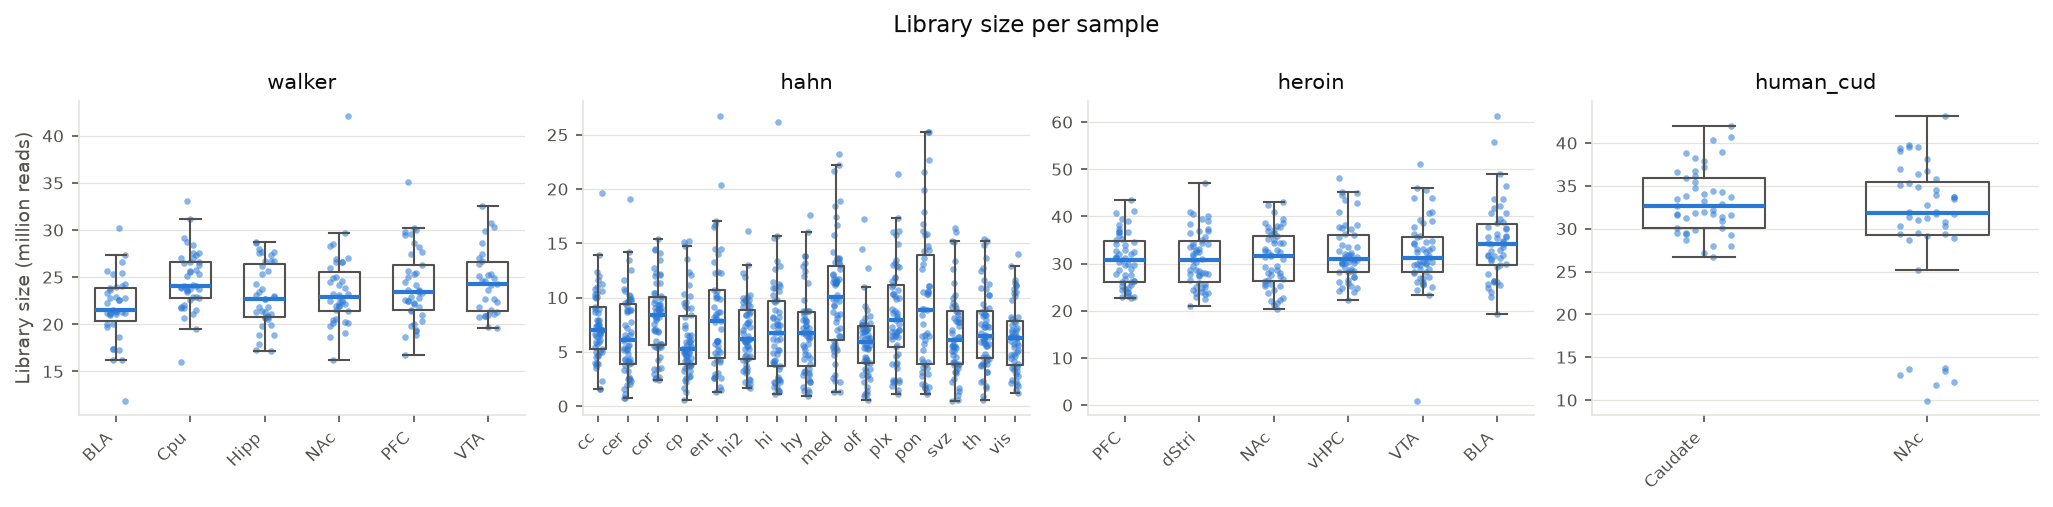

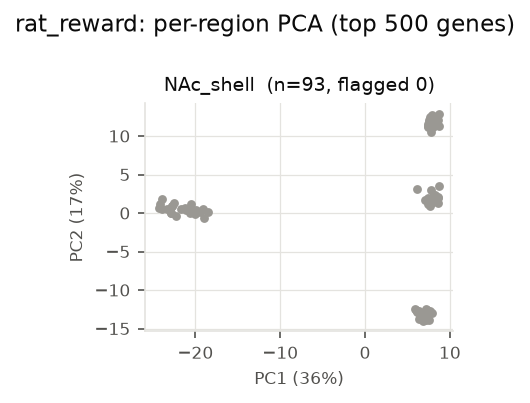

In [5]:
from IPython.display import Image, display
figs = cfg["paths"]["figures"]
display(Image(figs / "qc_library_size.png"))
display(Image(figs / "qc_pca_rat_reward.png"))

Text(0.5, 1.0, 'Human NAc library size by plate column')

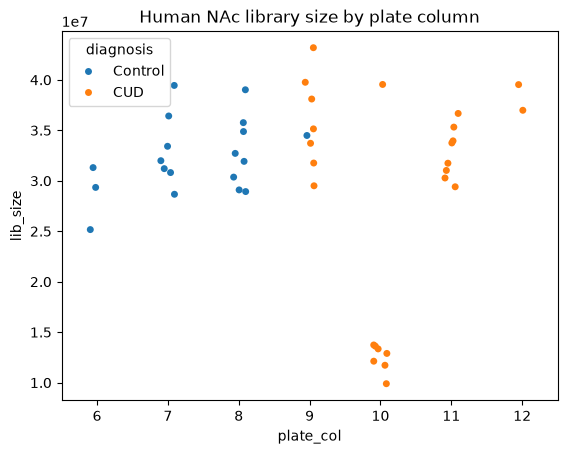

In [12]:
h = lib[(lib["dataset"] == "human_cud") & (lib["region"] == "NAc")].merge(
    human.meta[["well"]], left_on="sample", right_index=True)
h["plate_col"] = h["well"].str[1:].astype(int)
sns.stripplot(data=h, x="plate_col", y="lib_size", hue="diagnosis")
plt.title("Human NAc library size by plate column")

Text(0.5, 1.0, 'Hahn corpus callosum PCA by sex')

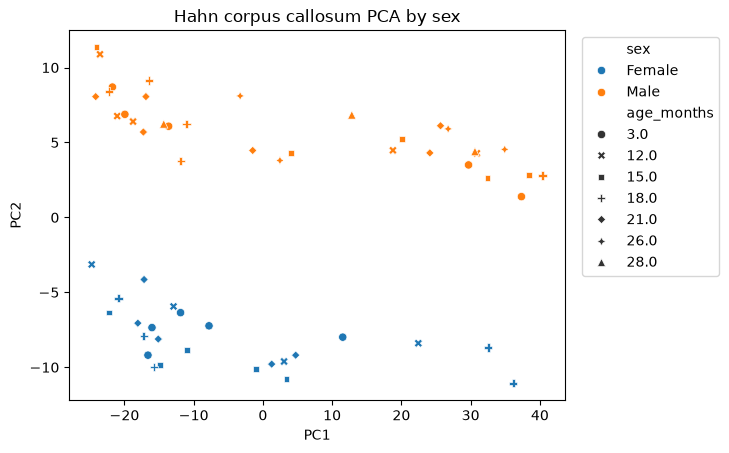

In [9]:
s = pca[(pca["dataset"] == "hahn") & (pca["region"] == "cc")]
sns.scatterplot(data=s, x="PC1", y="PC2", hue="sex", style="age_months")
plt.legend(bbox_to_anchor=(1.02, 1))
plt.title("Hahn corpus callosum PCA by sex")

In [13]:
pca.query("dataset == 'heroin' and region == 'VTA'").sort_values("knn_z", ascending=False).head()

,sample,dataset,region,group,PC1,PC2,PC1_var,PC2_var,knn_dist,knn_z,outlier,sex,age_months,diagnosis
1237,V-261,heroin,VTA,HH,96.272211,4.655685,0.470135,0.164804,97.028326,53.737616,True,NaN,NaN,NaN
1264,V-292,heroin,VTA,S24,0.491108,7.992914,0.470135,0.164804,21.203923,7.298973,True,NaN,NaN,NaN
1243,V-299,heroin,VTA,H24,0.338159,-0.589784,0.470135,0.164804,15.176727,3.607617,True,NaN,NaN,NaN
1248,V-283,heroin,VTA,SS,-1.184574,6.492967,0.470135,0.164804,14.245445,3.037254,False,NaN,NaN,NaN
1279,V-298,heroin,VTA,H24,-2.945723,-3.430400,0.470135,0.164804,13.714492,2.712072,False,NaN,NaN,NaN
